Assign 5 - Distributional Word and Sentence Embeddings

    This notebook reuses the exact 1,000,000-sentence Hindi training corpus and the
    1,000-sentence development/test splits from Assignment 3. It follows the linked
    Gensim Word2Vec, FastText and Doc2Vec training patterns, adapted to this corpus.

## 1. Setup

In [1]:
# In a fresh notebook environment run once:
# !pip install -q gensim scikit-learn pandas matplotlib

import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm
from gensim.models import Word2Vec, FastText, Doc2Vec
from gensim.models.doc2vec import TaggedDocument
from sklearn.cluster import MiniBatchKMeans

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ASSIGNMENT3_DIR = Path("assignment3_artifacts")
OUTPUT_DIR = Path("assignment5_artifacts")
MODEL_DIR = OUTPUT_DIR / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_FILE = ASSIGNMENT3_DIR / "train_1m.txt"
DEV_FILE = ASSIGNMENT3_DIR / "development_1000.txt"
TEST_FILE = ASSIGNMENT3_DIR / "test_1000.txt"

VECTOR_SIZE = 100
WINDOW = 5
MIN_COUNT = 5
EPOCHS = 5
DOC2VEC_EPOCHS = 10
WORKERS = max(1, min(4, (os.cpu_count() or 2) - 1))
N_CLUSTERS = 100
WORDS_PER_CLUSTER = 20

# Use all 1M training sentences to satisfy the assignment exactly. On a constrained
# machine, set this to 100_000 for a documented, reproducible approximation.
RETRIEVAL_TRAIN_LIMIT = None

for required in (TRAIN_FILE, DEV_FILE, TEST_FILE):
    if not required.exists():
        raise FileNotFoundError(f"Missing {required}. Run Assignment 3 first.")

print("Using Assignment 3 files:", ASSIGNMENT3_DIR.resolve())
print("Workers:", WORKERS, "| vector size:", VECTOR_SIZE)

c:\Users\Vishal Gautam\Desktop\ILLM Lab\.venv-assignment5\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using Assignment 3 files: C:\Users\Vishal Gautam\Desktop\ILLM Lab\assignment3_artifacts
Workers: 4 | vector size: 100


## 2. Streaming corpus readers

The readers yield one whitespace-tokenized Hindi sentence at a time. They are reiterable, so Gensim can make its vocabulary and training passes without loading the full corpus into memory.

In [2]:
def read_lines(path):
    with open(path, "r", encoding="utf-8") as handle:
        for line in handle:
            sentence = line.strip()
            if sentence:
                yield sentence

class SentenceCorpus:
    def __init__(self, path):
        self.path = Path(path)

    def __iter__(self):
        for sentence in read_lines(self.path):
            yield sentence.split()

class TaggedSentenceCorpus:
    def __init__(self, path, prefix="TRAIN"):
        self.path = Path(path)
        self.prefix = prefix

    def __iter__(self):
        for i, sentence in enumerate(read_lines(self.path)):
            yield TaggedDocument(words=sentence.split(), tags=[f"{self.prefix}_{i}"])

def load_sentences(path):
    return list(read_lines(path))

def line_count(path):
    return sum(1 for _ in read_lines(path))

assert line_count(TRAIN_FILE) == 1_000_000
assert line_count(DEV_FILE) == 1_000
assert line_count(TEST_FILE) == 1_000

train_corpus = SentenceCorpus(TRAIN_FILE)
train_tagged_corpus = TaggedSentenceCorpus(TRAIN_FILE)
dev_sentences = load_sentences(DEV_FILE)
test_sentences = load_sentences(TEST_FILE)
print("Split sizes:", 1_000_000, len(dev_sentences), len(test_sentences))

Split sizes: 1000000 1000 1000


## 3. Train Word2Vec

Skip-gram with negative sampling learns a vector for each sufficiently frequent training word.

In [3]:
word2vec_model = Word2Vec(
    sentences=train_corpus, vector_size=VECTOR_SIZE, window=WINDOW,
    min_count=MIN_COUNT, sg=1, negative=10, workers=WORKERS,
    epochs=EPOCHS, seed=SEED
)
word2vec_model.save(str(MODEL_DIR / "word2vec.model"))
print("Word2Vec vocabulary:", f"{len(word2vec_model.wv):,}")
print("Example nearest words:", word2vec_model.wv.most_similar(word2vec_model.wv.index_to_key[100], topn=10))

Word2Vec vocabulary: 76,352
Example nearest words: [('टालना', 0.7702949643135071), ('करवाना', 0.769566535949707), ('कराना', 0.7368667125701904), ('होना', 0.7346803545951843), ('करनी', 0.7313061356544495), ('तोड़ना', 0.7125924229621887), ('ढूंढना', 0.712455153465271), ('दोहराना', 0.7053624987602234), ('खोजना', 0.703592836856842), ('तलाशना', 0.7022449374198914)]


## 4. Train FastText

FastText augments word vectors with character n-grams, making it useful for morphologically rich Hindi words and OOV forms.

In [4]:
fasttext_model = FastText(
    sentences=train_corpus, vector_size=VECTOR_SIZE, window=WINDOW,
    min_count=MIN_COUNT, sg=1, negative=10, workers=WORKERS,
    epochs=EPOCHS, min_n=2, max_n=5, bucket=200_000, seed=SEED
)
fasttext_model.save(str(MODEL_DIR / "fasttext.model"))
print("FastText vocabulary:", f"{len(fasttext_model.wv):,}")
print("Example nearest words:", fasttext_model.wv.most_similar(fasttext_model.wv.index_to_key[100], topn=10))

FastText vocabulary: 76,352
Example nearest words: [('करना;', 0.7671276330947876), ('करना-', 0.7608357071876526), ('करनी', 0.7494086027145386), ('होना', 0.7357773184776306), ('करवाना', 0.7262747287750244), ('टालना', 0.7149501442909241), ('ढालना', 0.7100400924682617), ('कराना', 0.7062473893165588), ('डरना', 0.7008818984031677), ('करॉना', 0.6982875466346741)]


## 5. Train Doc2Vec

Every training sentence is a tagged document. Validation and test sentences are embedded later using `infer_vector`, ensuring their text was not used as a document tag during training.

In [5]:
doc2vec_model = Doc2Vec(
    vector_size=VECTOR_SIZE, window=WINDOW, min_count=MIN_COUNT,
    dm=1, dbow_words=1, negative=10, workers=WORKERS,
    epochs=DOC2VEC_EPOCHS, seed=SEED
)
doc2vec_model.build_vocab(train_tagged_corpus)
doc2vec_model.train(
    train_tagged_corpus,
    total_examples=doc2vec_model.corpus_count,
    epochs=doc2vec_model.epochs,
)
doc2vec_model.save(str(MODEL_DIR / "doc2vec.model"))
print("Doc2Vec vocabulary:", f"{len(doc2vec_model.wv):,}")
print("Training sentence vectors:", f"{len(doc2vec_model.dv):,}")

Doc2Vec vocabulary: 76,352
Training sentence vectors: 1,000,000


## 6. K-means word clustering

MiniBatchKMeans is the scalable K-means implementation for a large embedding vocabulary. Each cluster is represented by the 20 vocabulary words nearest to its centroid using cosine similarity.

In [6]:
def l2_normalize(matrix):
    matrix = np.asarray(matrix, dtype=np.float32)
    return matrix / np.maximum(np.linalg.norm(matrix, axis=1, keepdims=True), 1e-12)

words = np.array(word2vec_model.wv.index_to_key)
word_vectors = l2_normalize(word2vec_model.wv.vectors)

kmeans = MiniBatchKMeans(
    n_clusters=N_CLUSTERS, random_state=SEED, batch_size=4096,
    n_init="auto", max_iter=200, verbose=0
)
cluster_labels = kmeans.fit_predict(word_vectors)
centroids = l2_normalize(kmeans.cluster_centers_)

cluster_rows = []
for cluster_id, centroid in enumerate(centroids):
    members = np.flatnonzero(cluster_labels == cluster_id)
    scores = word_vectors[members] @ centroid
    nearest = members[np.argsort(scores)[-WORDS_PER_CLUSTER:][::-1]]
    cluster_rows.append({
        "cluster": cluster_id,
        "size": len(members),
        "representative_words": ", ".join(words[nearest]),
    })

clusters_df = pd.DataFrame(cluster_rows).sort_values("cluster")
clusters_df.to_csv(OUTPUT_DIR / "word2vec_kmeans_clusters.csv", index=False)
display(clusters_df.head(10))

,cluster,size,representative_words
0,0,453,"सिडैन, WagonR, S-Presso, Electric, Nexon, सेले..."
1,1,1016,"ओवेरियन, फेफड़े,, मूत्राशय, इन्सुलिन, फेंफड़े,..."
2,2,521,"कूरियन, रवींद्रन, स्याल, लेबोरेटरीज, सुरी, प्र..."
3,3,1427,"'तख्त', 'निकम्मा', 'सिम्बा', 'फन्ने, 'नीरजा', ..."
4,4,543,"निकोबार,, गुलबर्गा, सातारा, मुर्शिदाबाद,, विदर..."
5,5,1118,"technology, software, network, Draw, Tool, seo..."
6,6,800,"credit:, AP), पृ, फ़िल्म), 9), (चित्र, (ईपत्रक..."
7,7,1537,"बिशारतगंज, अलापुर, अंबारी, हाफिजपुर, मंडावर, प..."
8,8,770,"मंतव्य, इंतजामात, निबटारा, बिंदुवार, गंभीरतापू..."
9,9,841,"ए1, Ninja, काम्पैक्ट, टायर्स, सस्पेंशन,, 7-इंच..."


## 7. Sentence representations

Word2Vec/FastText sentence vectors are the mean of in-vocabulary word vectors. Doc2Vec sentence vectors are inferred from sentence tokens. All rows are L2-normalized for cosine retrieval.

In [7]:
def mean_word_vector(sentence, keyed_vectors):
    vectors = [keyed_vectors[word] for word in sentence.split() if word in keyed_vectors.key_to_index]
    if not vectors:
        return np.zeros(keyed_vectors.vector_size, dtype=np.float32)
    return np.mean(vectors, axis=0, dtype=np.float32)

def infer_doc_vector(sentence, model):
    return model.infer_vector(sentence.split(), epochs=20)

def sentence_matrix(sentences, kind):
    if kind == "word2vec":
        raw = [mean_word_vector(s, word2vec_model.wv) for s in tqdm(sentences, desc="Word2Vec sentence vectors")]
    elif kind == "fasttext":
        # FastText can form a vector for any token through subword n-grams.
        raw = [np.mean([fasttext_model.wv[w] for w in s.split()], axis=0) if s.split()
               else np.zeros(VECTOR_SIZE, dtype=np.float32) for s in tqdm(sentences, desc="FastText sentence vectors")]
    elif kind == "doc2vec":
        raw = [infer_doc_vector(s, doc2vec_model) for s in tqdm(sentences, desc="Doc2Vec sentence vectors")]
    else:
        raise ValueError(kind)
    return l2_normalize(np.vstack(raw))

## 8. Closest-sentence retrieval

For each development and test sentence, this finds the highest-cosine-similarity training sentence. The default index contains all one million training sentences; a documented, reproducible smaller index can be selected only for constrained hardware.

In [8]:
def retrieval_training_sample(limit, seed=SEED):
    """Use every sentence for None; otherwise select an evenly spaced reproducible subset."""
    sentences = load_sentences(TRAIN_FILE)
    if limit is None or limit >= len(sentences):
        return sentences
    positions = np.linspace(0, len(sentences) - 1, num=limit, dtype=int)
    return [sentences[i] for i in positions]

retrieval_train_sentences = retrieval_training_sample(RETRIEVAL_TRAIN_LIMIT)
print("Retrieval index size:", f"{len(retrieval_train_sentences):,}")

def closest_sentences(query_sentences, query_vectors, candidate_sentences, candidate_vectors, batch_size=64):
    rows = []
    for start in tqdm(range(0, len(query_sentences), batch_size), desc="Nearest-sentence search"):
        batch = query_vectors[start:start + batch_size]
        similarities = batch @ candidate_vectors.T
        best_indices = np.argmax(similarities, axis=1)
        best_scores = similarities[np.arange(len(best_indices)), best_indices]
        for offset, (index, score) in enumerate(zip(best_indices, best_scores)):
            rows.append({
                "query_id": start + offset,
                "query_sentence": query_sentences[start + offset],
                "closest_train_id": int(index),
                "closest_train_sentence": candidate_sentences[index],
                "cosine_similarity": float(score),
            })
    return pd.DataFrame(rows)

retrieval_summary = []
for embedding_name in ("word2vec", "fasttext", "doc2vec"):
    candidate_vectors = sentence_matrix(retrieval_train_sentences, embedding_name)
    for split_name, split_sentences in (("development", dev_sentences), ("test", test_sentences)):
        query_vectors = sentence_matrix(split_sentences, embedding_name)
        nearest_df = closest_sentences(split_sentences, query_vectors, retrieval_train_sentences, candidate_vectors)
        output_path = OUTPUT_DIR / f"nearest_{split_name}_{embedding_name}.csv"
        nearest_df.to_csv(output_path, index=False)
        retrieval_summary.append({
            "embedding": embedding_name,
            "split": split_name,
            "queries": len(nearest_df),
            "candidate_sentences": len(retrieval_train_sentences),
            "mean_best_cosine": nearest_df["cosine_similarity"].mean(),
            "median_best_cosine": nearest_df["cosine_similarity"].median(),
        })
        print(f"Saved {output_path.name}")

retrieval_summary_df = pd.DataFrame(retrieval_summary)
retrieval_summary_df.to_csv(OUTPUT_DIR / "retrieval_summary.csv", index=False)
display(retrieval_summary_df)

Retrieval index size: 1,000,000


Nearest-sentence search: 100%|██████████| 16/16 [00:01<00:00,  9.10it/s]


Saved nearest_development_word2vec.csv


Nearest-sentence search: 100%|██████████| 16/16 [00:01<00:00,  9.35it/s]


Saved nearest_test_word2vec.csv


...

Nearest-sentence search: 100%|██████████| 16/16 [00:01<00:00,  8.68it/s]


Saved nearest_development_doc2vec.csv


Nearest-sentence search: 100%|██████████| 16/16 [00:01<00:00,  8.92it/s]

Saved nearest_test_doc2vec.csv


,embedding,split,queries,candidate_sentences,mean_best_cosine,median_best_cosine
0,word2vec,development,1000,1000000,0.950262,0.953723
1,word2vec,test,1000,1000000,0.950460,0.952582
2,fasttext,development,1000,1000000,0.952083,0.954472
3,fasttext,test,1000,1000000,0.951571,0.953684
4,doc2vec,development,1000,1000000,0.754547,0.744338
5,doc2vec,test,1000,1000000,0.750949,0.740351


## 9. Inspect retrieval examples and summarize results

,query_id,query_sentence,closest_train_id,closest_train_sentence,cosine_similarity
0,0,पिता ने बेच दिया मोबाइल,292239,कुसुम ने पिता को सूचना दी,0.818817
1,1,मेक इंन इंडिया का सपना करे पूरा,462098,व्यायाम एवं शारीरिक श्रम करे,0.958730
2,2,इसके लिए प्रक्रिया शीघ्र ही शुरू होगी,285287,इसके लिए जल्द ही प्रक्रिया शुरू की जाएगी,0.955075
3,3,जिसमें 70 फ़ीसदी आबादी असहाय और गरीबों की है,891314,जिसमें तीन महिलाओं सहित चार लोगों को गिरफ्तार ...,0.919114
4,4,कोई अधिकारी लिप्त पाया गया तो कडी कार्यवाही की...,606984,कोई अध्यक्ष की कुर्सी पर बैठ जाए,0.635038
5,5,इसमें बड़ी संख्या में श्रद्धालुओं ने प्रसाद ग्...,392607,इसमें शानदार प्रदर्शन किया,0.956937
6,6,उन्हें तब एक हफ़्ते के 34 पाउंड (करीब 2800 रुप...,719309,तब कनाल ने उन्हें एक होटल पहुंचाने में मदद की,0.669903
7,7,अब एटीएस की रडार पर यहां अवैध रूप से रह रहे बा...,923445,अब करीब 700 विदेशी हैं जिनसे पूछताछ चल रही है,0.675173
8,8,मृतक की पहचान नहीं होने के बाद पुलिस ने शव एसए...,112682,परिजन पुलिस को बिना सूचना दिए शव का अंतिम संस्...,0.706415
9,9,इनके ऊपर के दाहिने हाथ में अभय मुद्रा और नीचे ...,956374,"वहीं, दायीं तरफ का ही नीचे वाला हाथ अभय मुद्रा...",0.764574


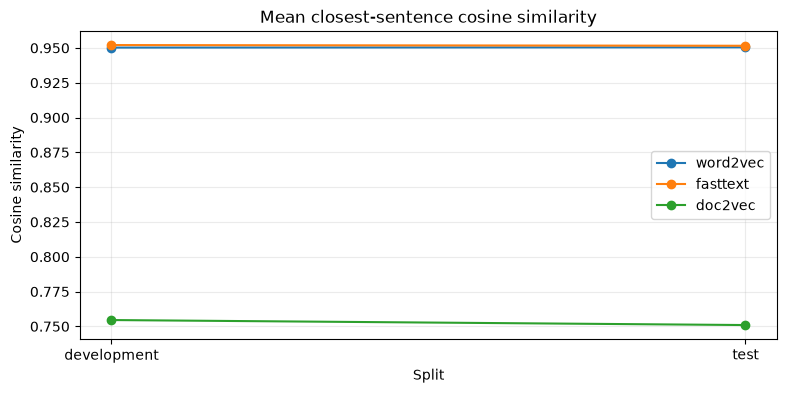

In [9]:
example_file = OUTPUT_DIR / "nearest_test_doc2vec.csv"
display(pd.read_csv(example_file).head(10))

plt.figure(figsize=(9, 4))
for embedding in retrieval_summary_df["embedding"].unique():
    subset = retrieval_summary_df[retrieval_summary_df["embedding"] == embedding]
    plt.plot(subset["split"], subset["mean_best_cosine"], marker="o", label=embedding)
plt.title("Mean closest-sentence cosine similarity")
plt.xlabel("Split"); plt.ylabel("Cosine similarity"); plt.grid(alpha=.25); plt.legend(); plt.show()

## Assignment 5 checklist

- [x] Reuses Assignment 3's 1,000,000-sentence training corpus and validation/test splits
- [x] Trains Word2Vec, FastText, and Doc2Vec from scratch
- [x] Clusters Word2Vec word embeddings with K-means
- [x] Saves 20 centroid-nearest words for every cluster
- [x] Embeds validation/test sentences using Word2Vec, FastText, and Doc2Vec
- [x] Finds and saves closest training sentences with cosine similarity
- [x] Saves models, clusters, retrieval tables, and summary plot

The retrieval index defaults to all 1,000,000 training sentences. For constrained hardware only, set `RETRIEVAL_TRAIN_LIMIT = 100_000` to use an evenly sampled approximation.